# ImageNet initialization

Main text

In [1]:
from pathlib import Path
import sys
from IPython.display import display, HTML, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/pretrained.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
from gw import classification_report as report
config = report.read(ROOT, 'pretrained')
reference = report.paper(ROOT, 'main_pretrained')
runs, mean, sd, sources = report.saved_evaluation(ROOT, config)
from gw.publication_ui import folded_table, folded_comparison, compact_settings

## Results

Test set · 10 seeds · mean ± sample SD.

In [2]:
report.show(report.table_frame(mean, sd, reference))
folded_table('Checkpoint sources', sources)

,,Runs,Model evaluations,Source
Dataset,Model,,,
Schwegmann SAR,DenseNet-121,30,30,Replayed checkpoint evaluation
OpenSARShip2,ResNet-18,30,30,Replayed checkpoint evaluation
FUSAR-Ship-5 proxy,VGG-16,30,30,Replayed checkpoint evaluation
OCTDL,Swin-Tiny,30,30,Saved model evaluation


## Calibration

Diamonds: mean; bars: sample SD; circles: individual seeds.

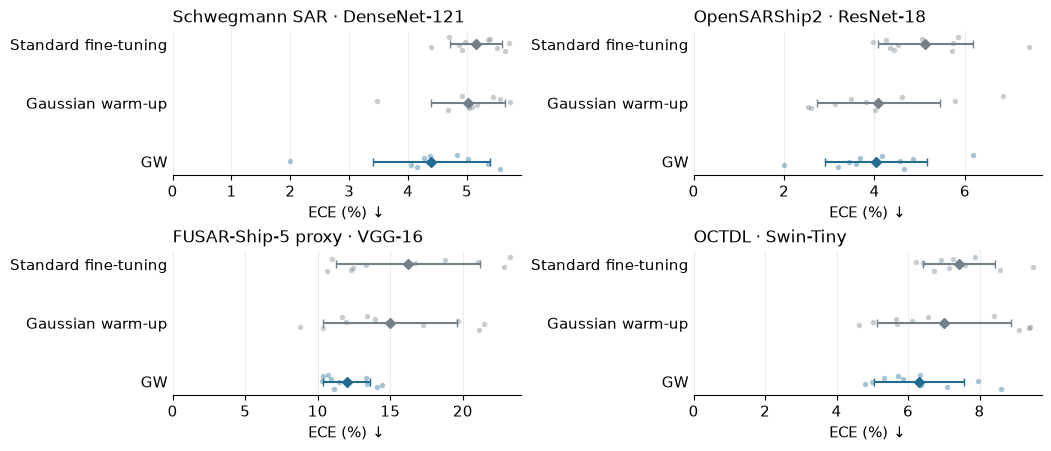

In [3]:
figure = report.plot(runs, mean, sd, ROOT / 'assets/figures/pretrained_ece.png')
display(figure)
import matplotlib.pyplot as plt
plt.close(figure)

## Settings

In [4]:
display(HTML('<details><summary>Settings</summary><div style="overflow:auto;max-height:420px">'+compact_settings(report.settings(config)).to_html(index=False, border=0)+'</div></details>'))

Dataset,Model,Method,Images,Input size,Supervised epochs,Warm-up epochs,Batch size,Learning rate,Weight decay,L,p,ρ
Schwegmann SAR,DenseNet-121,Standard fine-tuning,1471,21,50,0,256,0.00003,0.0001,NaN,NaN,NaN
Schwegmann SAR,DenseNet-121,Gaussian warm-up,1471,21,50,5,256,0.00003,0.0001,NaN,NaN,NaN
Schwegmann SAR,DenseNet-121,GW,1471,21,50,5,256,0.00003,0.0001,8.0,0.50,0.50
Schwegmann SAR,DenseNet-121,GW,1471,21,50,5,256,0.00003,0.0001,4.0,0.25,0.50
Schwegmann SAR,DenseNet-121,GW,1471,21,50,5,256,0.00003,0.0001,4.0,0.25,0.25
Schwegmann SAR,DenseNet-121,GW,1471,21,50,5,256,0.00003,0.0001,8.0,0.25,0.50
Schwegmann SAR,DenseNet-121,GW,1471,21,50,5,256,0.00003,0.0001,8.0,0.50,1.00
Schwegmann SAR,DenseNet-121,GW,1471,21,50,5,256,0.00003,0.0001,8.0,0.25,1.00
Schwegmann SAR,DenseNet-121,GW,1471,21,50,5,256,0.00003,0.0001,8.0,0.25,0.25
OpenSARShip2,ResNet-18,Standard fine-tuning,951,128,100,0,128,0.00003,0.0001,NaN,NaN,NaN


## Inference

Set `RUN_INFERENCE = True` to evaluate the checkpoints.

In [5]:
RUN_INFERENCE = False
DATASET = None
evaluation = report.select_dataset(config, DATASET)
evaluation_reference = report.select_reference(reference, evaluation)
if RUN_INFERENCE:
    from gw.inference_process import run
    directory = run(ROOT, evaluation)
else:
    directory = ROOT / 'results/pretrained/gpu_predictions'
if RUN_INFERENCE:
    fresh, fresh_mean, fresh_sd = report.calculate(ROOT, evaluation, directory)
    report.show(report.table_frame(fresh_mean, fresh_sd, evaluation_reference))
    folded_comparison(report.comparison(fresh_mean, fresh_sd, evaluation_reference))
else:
    pass

## Complete table

In [6]:
from gw.publication_ui import folded_table
full_reference = report.paper(ROOT, 's5_pretrained')
folded_table('All metrics', report.table_frame(mean, sd, full_reference))
folded_comparison(report.comparison(mean, sd, full_reference))
